# Tile Grid Map

**Family:** Spatial &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Spatial:* Use when precise locations or geographic patterns matter more than anything else.

## Design purpose

Replaces every region with an equal-sized square laid out roughly in its geographic position. Each state gets the same visual weight, which fixes the choropleth's large-area bias.

## When to use

- Every region should count equally (US states, EU countries, districts)
- Small regions (RI, DE, DC) would vanish on a real map
- You want a compact, label-friendly map that works in print

## Avoid when

- Exact geography, distance or shape matters
- The audience is unfamiliar with the regions and needs the real outlines to orient

## Alternatives

- Choropleth map
- Hexagon tile map
- Sorted bar chart

## Design tips

- Label each tile with its code, and switch the text to white on dark tiles
- Use the same one-hue sequential scale you would use on a choropleth

## Example

The same illustrative state uninsured rates as the choropleth, on a tile grid.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
STATES = ["AL", "AK", "AZ", "AR", "CA", "CO", "CT", "DE", "DC", "FL", "GA", "HI", "ID", "IL", "IN",
          "IA", "KS", "KY", "LA", "ME", "MD", "MA", "MI", "MN", "MS", "MO", "MT", "NE", "NV", "NH",
          "NJ", "NM", "NY", "NC", "ND", "OH", "OK", "OR", "PA", "RI", "SC", "SD", "TN", "TX", "UT",
          "VT", "VA", "WA", "WV", "WI", "WY"]

GRID = {"AK": (0, 0), "ME": (0, 11), "VT": (1, 10), "NH": (1, 11),
        "WA": (2, 1), "ID": (2, 2), "MT": (2, 3), "ND": (2, 4), "MN": (2, 5), "IL": (2, 6),
        "WI": (2, 7), "MI": (2, 8), "NY": (2, 9), "RI": (2, 10), "MA": (2, 11),
        "OR": (3, 1), "NV": (3, 2), "WY": (3, 3), "SD": (3, 4), "IA": (3, 5), "IN": (3, 6),
        "OH": (3, 7), "PA": (3, 8), "NJ": (3, 9), "CT": (3, 10),
        "CA": (4, 1), "UT": (4, 2), "CO": (4, 3), "NE": (4, 4), "MO": (4, 5), "KY": (4, 6),
        "WV": (4, 7), "VA": (4, 8), "MD": (4, 9), "DE": (4, 10),
        "AZ": (5, 2), "NM": (5, 3), "KS": (5, 4), "AR": (5, 5), "TN": (5, 6), "NC": (5, 7),
        "SC": (5, 8), "DC": (5, 9),
        "OK": (6, 4), "LA": (6, 5), "MS": (6, 6), "AL": (6, 7), "GA": (6, 8),
        "HI": (7, 0), "TX": (7, 4), "FL": (7, 9)}
rng = np.random.default_rng(8)
south = {"TX", "OK", "GA", "FL", "MS", "AL", "SC", "NC", "TN", "AR", "LA", "NM", "AZ", "NV", "WY"}
rate = [rng.normal(11.5 if s in south else 6.5, 1.6) for s in STATES]
df = pd.DataFrame({"state": STATES, "uninsured_pct": np.clip(rate, 2.5, 18).round(1)})
df["row"] = df["state"].map(lambda s: GRID[s][0])
df["col"] = df["state"].map(lambda s: GRID[s][1])
df.head()

,state,uninsured_pct,row,col
0,AL,8.7,6,7
1,AK,4.4,0,0
2,AZ,9.3,5,2
3,AR,10.9,5,5
4,CA,2.8,4,1


### Plot

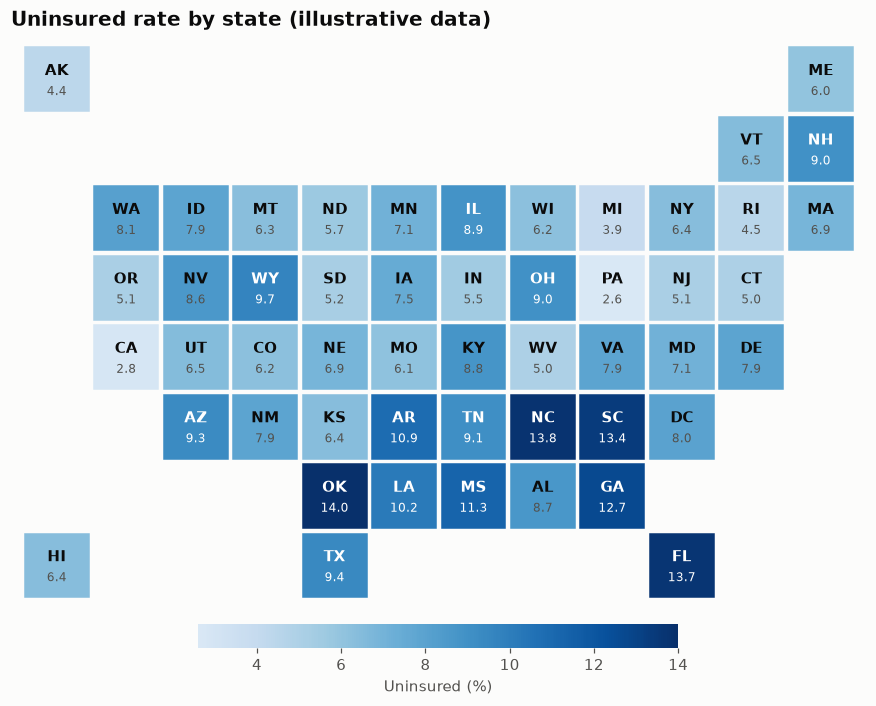

In [3]:
import matplotlib as mpl
norm = mpl.colors.Normalize(df["uninsured_pct"].min(), df["uninsured_pct"].max())
cmap = plt.get_cmap(SEQ_CMAP)
fig, ax = plt.subplots(figsize=(10, 6.5))
for _, r in df.iterrows():
    c = cmap(0.15 + 0.85 * norm(r.uninsured_pct))
    ax.add_patch(plt.Rectangle((r.col, -r.row), 0.92, 0.92, color=c))
    dark = norm(r.uninsured_pct) > 0.55
    ax.text(r.col + 0.46, -r.row + 0.58, r.state, ha="center", va="center", fontsize=10,
            fontweight="bold", color="white" if dark else "#0b0b0b")
    ax.text(r.col + 0.46, -r.row + 0.28, f"{r.uninsured_pct:.1f}", ha="center", va="center",
            fontsize=8, color="white" if dark else "#52514e")
ax.set_xlim(-0.2, 12.1); ax.set_ylim(-7.2, 1.1)
ax.set_aspect("equal"); ax.axis("off")
sm = mpl.cm.ScalarMappable(norm=norm, cmap=mpl.colors.ListedColormap(cmap(np.linspace(0.15, 1, 256))))
cb = fig.colorbar(sm, ax=ax, orientation="horizontal", fraction=0.04, pad=0.02, shrink=0.45)
cb.set_label("Uninsured (%)"); cb.outline.set_visible(False)
ax.set_title("Uninsured rate by state (illustrative data)")
fig.tight_layout()
plt.show()

## How to read it

Each square is one state, placed roughly where it sits geographically. Darker squares have higher rates, and DC and Rhode Island get the same weight as Texas.

---
Standalone script: [`tile_grid_map.py`](tile_grid_map.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)